# 02 — Perfil del histórico raw de MiBici

Diagnóstico **de solo lectura** del histórico (Fase 1, Objetivo 1). Las tablas se generan con `make profile` (`mibici/profiling.py`) en `reports/profiling/`; este notebook solo las lee, resume y grafica.

No se limpia, filtra ni transforma ningún registro. Los umbrales (p. ej. > 24 h) solo cuentan casos.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from mibici.config import FIGURES_DIR
from mibici.profiling import PROFILING_DIR

pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 200)

profile = pd.read_csv(PROFILING_DIR / 'raw_trips_profile.csv')
stations = pd.read_csv(PROFILING_DIR / 'station_month_counts.csv', dtype={'station_id': str})
daily = pd.read_csv(PROFILING_DIR / 'daily_trip_counts.csv', parse_dates=['date'])
nomenclature = pd.read_csv(PROFILING_DIR / 'nomenclature_stations.csv', dtype=str)
nomenclature_profile = pd.read_csv(PROFILING_DIR / 'nomenclature_profile.csv')

profile['period'] = pd.PeriodIndex.from_fields(
    year=profile['year'], month=profile['month'], freq='M'
)

2026-10-21 20:36:20.276 | INFO     | mibici.config:<module>:11 - PROJ_ROOT path is: /home/watson/projects/mibici


In [2]:
# Chart style: one hue, recessive grid and axes
SERIES = '#2a78d6'
MUTED = '#52514e'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#d6d5d0', 'axes.labelcolor': MUTED,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': '#0b0b0b',
    'axes.grid': True, 'grid.color': '#ebeae6', 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2, 'figure.dpi': 110,
})

## 1. Cobertura temporal y volumen

In [3]:
full = pd.period_range(profile['period'].min(), profile['period'].max(), freq='M')
print('Archivos de viajes:', len(profile))
print('Periodo:', profile['period'].min(), '→', profile['period'].max())
print('Meses faltantes:', sorted(set(full) - set(profile['period'])))
print('Registros totales:', f"{profile['n_rows'].sum():,}")
profile.groupby('year')['n_rows'].sum().to_frame('registros')

Archivos de viajes: 142
Periodo: 2014-12 → 2026-09
Meses faltantes: []
Registros totales: 39,078,984


,registros
year,
2014,23967
2015,469871
2016,941918
2017,2516534
2018,3403485
2019,4636652
2020,2866072
2021,3184410
2022,4202942


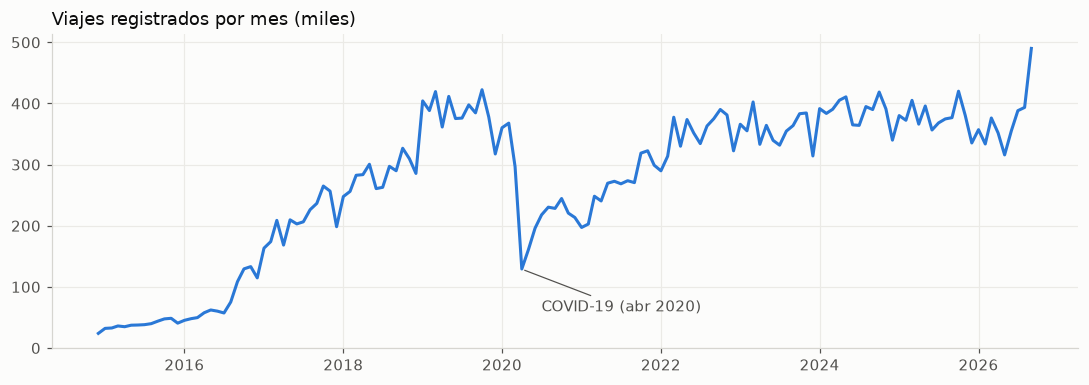

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
x = profile['period'].dt.to_timestamp()
ax.plot(x, profile['n_rows'] / 1000, color=SERIES)
ax.set_title('Viajes registrados por mes (miles)', loc='left')
ax.set_ylim(bottom=0)
ax.annotate('COVID-19 (abr 2020)', xy=(pd.Timestamp('2020-04-01'), 129),
            xytext=(pd.Timestamp('2020-07-01'), 60), color=MUTED,
            arrowprops={'arrowstyle': '-', 'color': MUTED, 'lw': 0.8})
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'trips_per_month.png')

## 2. Variantes de formato y esquema

In [5]:
profile['datetime_layout'] = (
    profile['format_slash_dayfirst_Inicio_del_viaje'].gt(0)
    .map({True: 'dd/mm/yyyy h:mm', False: 'yyyy-mm-dd hh:mm:ss'})
)
variants = profile.groupby(
    ['encoding', 'quoted_header', 'line_ending', 'datetime_layout', 'raw_header'],
    dropna=False,
).agg(files=('filename', 'size'), first=('period', 'min'), last=('period', 'max'))
variants

files    first     last
encoding quoted_header line_ending datetime_layout     raw_header                                                                 
latin-1  False         crlf        dd/mm/yyyy h:mm     Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,In...      3  2023-11  2024-10
         True          lf          yyyy-mm-dd hh:mm:ss "Viaje_Id","Usuario_Id","Genero","A}äe_nacimien...      2  2024-02  2024-05
                                                       "Viaje_Id","Usuario_Id","Genero","Año_de_nacimi...     38  2021-06  2026-01
utf-8    False         lf          yyyy-mm-dd hh:mm:ss Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,In...     78  2014-12  2021-05
         True          lf          yyyy-mm-dd hh:mm:ss "Viaje_Id","Usuario_Id","Genero","Año_de_nacimi...     21  2022-12  2026-09

In [6]:
print('Todos los encabezados con el layout esperado:', profile['header_matches_layout'].all())
profile.loc[profile['datetime_layout'] != 'yyyy-mm-dd hh:mm:ss',
            ['filename', 'n_rows', 'slash_first_field_gt_12', 'slash_second_field_gt_12', 'start_outside_file_month']]

Todos los encabezados con el layout esperado: True


,filename,n_rows,slash_first_field_gt_12,slash_second_field_gt_12,start_outside_file_month
107,datos_abiertos_2023_11.csv,384464,233833,0,0
117,datos_abiertos_2024_09.csv,390072,225893,0,0
118,datos_abiertos_2024_10.csv,418690,261508,0,0


## 3. Calidad por columna (totales sobre todo el histórico)

In [7]:
prefixes = ('empty_', 'missing_token_', 'decimal_text_', 'non_numeric_', 'unparsed_')
quality = profile[[c for c in profile.columns if c.startswith(prefixes)]].sum()
quality = quality[quality > 0].sort_values(ascending=False).to_frame('casos')
quality['% del total'] = (quality['casos'] / profile['n_rows'].sum() * 100).round(3)
quality

,casos,% del total
decimal_text_Año_de_nacimiento,15965638,40.855
missing_token_Genero,131497,0.336
empty_Año_de_nacimiento,51283,0.131
missing_token_Año_de_nacimiento,30368,0.078
empty_Genero,13011,0.033


In [8]:
checks = ['start_outside_file_month', 'duration_negative', 'duration_zero',
          'duration_lt_60s', 'duration_gt_24h', 'duplicated_rows',
          'duplicated_Viaje_Id', 'birth_year_lt_1920', 'birth_year_gt_file_year',
          'same_origin_destination']
summary = profile[checks].sum().to_frame('casos')
summary['% del total'] = (summary['casos'] / profile['n_rows'].sum() * 100).round(3)
summary

,casos,% del total
start_outside_file_month,0,0.000
duration_negative,0,0.000
duration_zero,55038,0.141
duration_lt_60s,1214387,3.108
duration_gt_24h,1832,0.005
duplicated_rows,758,0.002
duplicated_Viaje_Id,758,0.002
birth_year_lt_1920,2689,0.007
birth_year_gt_file_year,0,0.000
same_origin_destination,2725187,6.974


In [9]:
profile.loc[profile['duplicated_rows'] > 0, ['filename', 'n_rows', 'duplicated_rows', 'duplicated_Viaje_Id']]

,filename,n_rows,duplicated_rows,duplicated_Viaje_Id
141,datos_abiertos_2026_09.csv,490056,758,758


In [10]:
profile[['duration_p50_s', 'duration_p95_s', 'duration_p99_s']].describe().round(0)

,duration_p50_s,duration_p95_s,duration_p99_s
count,142.0,142.0,142.0
mean,557.0,1428.0,1984.0
std,31.0,59.0,94.0
min,465.0,1233.0,1766.0
25%,556.0,1428.0,1931.0
50%,567.0,1443.0,1981.0
75%,574.0,1463.0,2036.0
max,600.0,1516.0,2393.0


## 4. Evolución de la red de estaciones

,min,max
period,,
2014,86,86
2015,84,115
2016,114,239
2017,235,236
2018,234,275
2019,273,274
2020,273,276
2021,274,300
2022,300,300


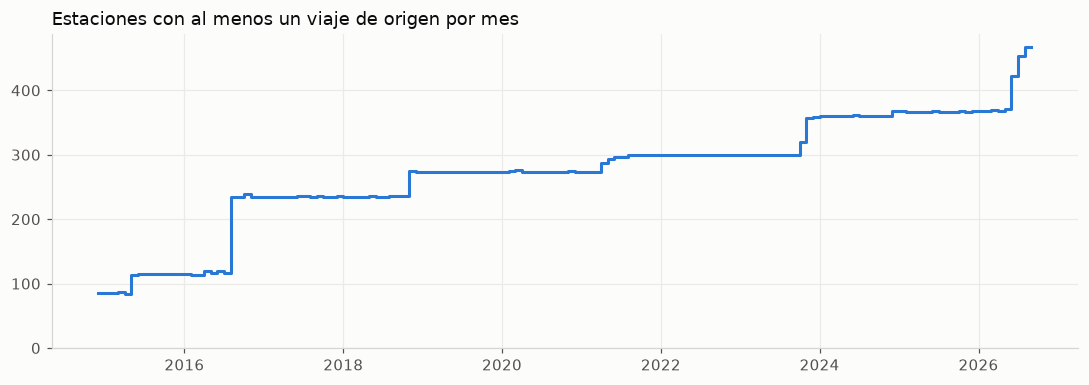

In [11]:
origin = stations[stations['role'] == 'origin'].copy()
origin['period'] = pd.PeriodIndex.from_fields(
    year=origin['year'], month=origin['month'], freq='M'
)
active = origin.groupby('period')['station_id'].nunique()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.step(active.index.to_timestamp(), active.values, where='post', color=SERIES)
ax.set_title('Estaciones con al menos un viaje de origen por mes', loc='left')
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'active_stations_per_month.png')
active.groupby(active.index.year).agg(['min', 'max'])

In [12]:
life = origin.groupby('station_id').agg(
    first=('period', 'min'), last=('period', 'max'),
    months=('period', 'nunique'), trips=('n_trips', 'sum'),
)
print('Estaciones por año de primera aparición:')
print(life['first'].dt.year.value_counts().sort_index().to_dict())
print('Estaciones sin actividad en el último mes:', (life['last'] < active.index.max()).sum())

Estaciones por año de primera aparición:
{2014: 86, 2015: 30, 2016: 125, 2017: 3, 2018: 42, 2019: 1, 2020: 1, 2021: 25, 2023: 59, 2024: 11, 2025: 3, 2026: 100}
Estaciones sin actividad en el último mes: 18


## 5. Nomenclatura vs. estaciones observadas en viajes

In [13]:
nomenclature_profile.T

,0
filename,nomenclatura_2026_09.csv
encoding,utf-8
columns,id|name|latitude|longitude|dpcapacity
columns_match_expected,True
n_rows,484
n_unique_id,484
duplicated_id,0
duplicated_name,0
non_numeric_id,0
empty_id,0


In [14]:
status = nomenclature['name'].str.startswith('ex-').map({True: 'retirada (ex-)', False: 'vigente'})
print(status.value_counts().to_dict())
trip_ids = set(stations['station_id'])
nom_ids = set(nomenclature['id'])
missing = stations[~stations['station_id'].isin(nom_ids)]
print('IDs en viajes:', len(trip_ids), '| IDs en nomenclatura:', len(nom_ids))
print('En viajes y no en nomenclatura:', sorted(trip_ids - nom_ids))
print('En nomenclatura sin viajes:', sorted(nom_ids - trip_ids))
missing.groupby(['station_id', 'role']).agg(
    first_year=('year', 'min'), last_year=('year', 'max'), trips=('n_trips', 'sum')
)

{'vigente': 470, 'retirada (ex-)': 14}


IDs en viajes: 486 | IDs en nomenclatura: 484
En viajes y no en nomenclatura: ['124', '405', '407']
En nomenclatura sin viajes: ['492']


first_year  last_year  trips
station_id role                                     
124        destination        2016       2020     65
           origin             2016       2020     63
405        destination        2026       2026      3
           origin             2026       2026      3
407        destination        2026       2026   2120
           origin             2026       2026   1957

## 6. Continuidad diaria

In [15]:
per_day = daily.groupby('date')['n_trips'].sum()
gaps = pd.date_range(per_day.index.min(), per_day.index.max()).difference(per_day.index)
print('Días con viajes:', len(per_day), '| días sin ningún viaje:', len(gaps))
baseline = per_day.rolling(29, center=True, min_periods=5).median()
per_day[per_day < 0.25 * baseline].to_frame('viajes')

Días con viajes: 4322 | días sin ningún viaje: 0


,viajes
date,
2015-03-15,258
2015-03-16,158
2015-12-25,279
2016-11-13,1006
2020-02-03,1778
2026-02-22,2275
